In [32]:
from ucimlrepo import fetch_ucirepo

absenteeism_at_work = fetch_ucirepo(id=445)
X = absenteeism_at_work.data.features
y = absenteeism_at_work.data.targets

absenteeism_at_work.variables[['name', 'role', 'type']]

,name,role,type
0,ID,ID,Integer
1,Reason for absence,Feature,Integer
2,Month of absence,Feature,Integer
3,Day of the week,Feature,Integer
4,Seasons,Feature,Integer
5,Transportation expense,Feature,Integer
6,Distance from Residence to Work,Feature,Integer
7,Service time,Feature,Integer
8,Age,Feature,Integer
9,Work load Average/day,Feature,Continuous


# 2) Analyse qualitative

Pas de colonne date : on reconstruit un index mensuel → série de 37 points (juil. 2007 → juil. 2010).

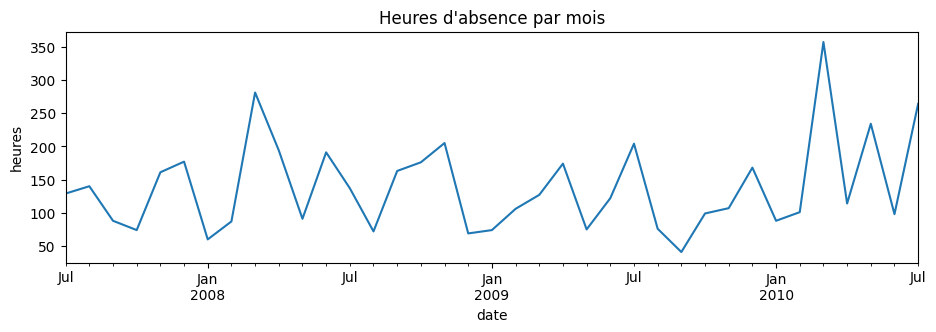

count     37.000000
mean     138.486486
std       69.229338
min       41.000000
25%       88.000000
50%      122.000000
75%      176.000000
max      357.000000
Name: Absenteeism time in hours, dtype: float64

In [33]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.concat([X, y], axis=1)
df = df[df['Month of absence'] != 0].copy()

month = df['Month of absence'].astype(int).to_numpy()
year = np.empty_like(month); y0 = 2007
for i, m in enumerate(month):
    if i > 0 and m < month[i-1]:
        y0 += 1
    year[i] = y0
df['date'] = pd.to_datetime(dict(year=year, month=month, day=1))

ts = df.groupby('date')['Absenteeism time in hours'].sum().asfreq('MS')

ts.plot(figsize=(11, 3), title="Heures d'absence par mois")
plt.ylabel('heures'); plt.show()
ts.describe()

### Tendance par moyenne mobile

MM centrée : fenêtre 12 mois lisse le cycle annuel, 3 mois pour le détail.

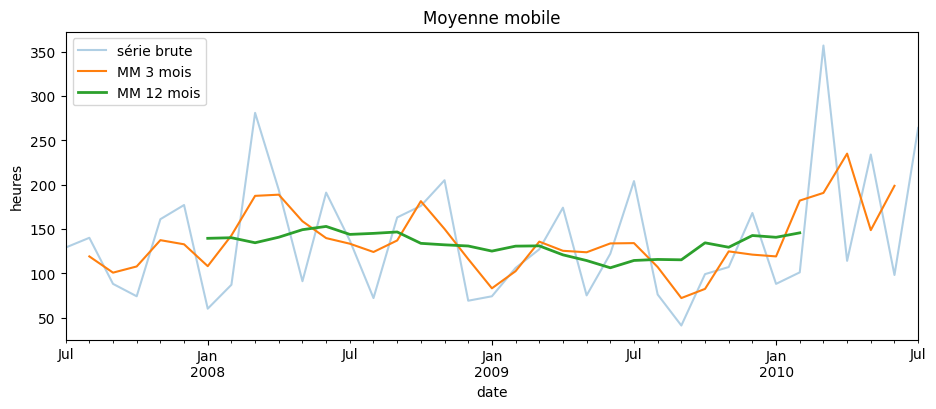

In [ ]:
ax = ts.plot(figsize=(11, 4), alpha=.35, label='série brute')
ts.rolling(3,  center=True).mean().plot(ax=ax, label='MM 3 mois')
ts.rolling(12, center=True).mean().plot(ax=ax, lw=2, label='MM 12 mois')
ax.set_title('Moyenne mobile'); ax.set_ylabel('heures')
ax.legend(); plt.show()

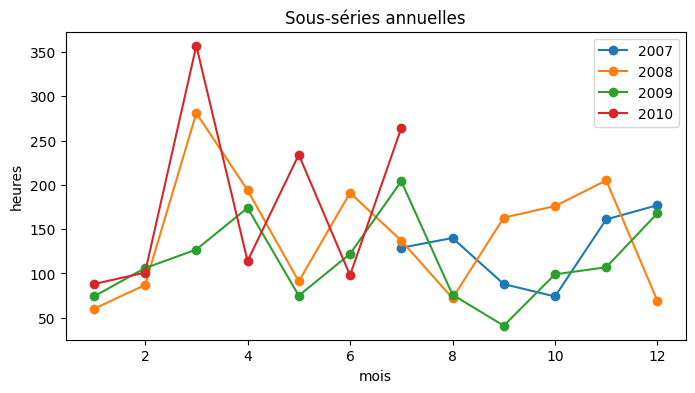

In [35]:
# sous-séries : une trajectoire par année
fig, ax = plt.subplots(figsize=(8, 4))
for yr, g in ts.groupby(ts.index.year):
    ax.plot(g.index.month, g.values, marker='o', label=str(yr))
ax.set_xlabel('mois')
ax.set_ylabel('heures')
ax.set_title('Sous-séries annuelles'); ax.legend()
plt.show()

### Décomposition saisonnière

Additive ($T{+}S{+}R$), multiplicative ($T{\cdot}S{\cdot}R$) par MM, puis STL (Loess, robuste).

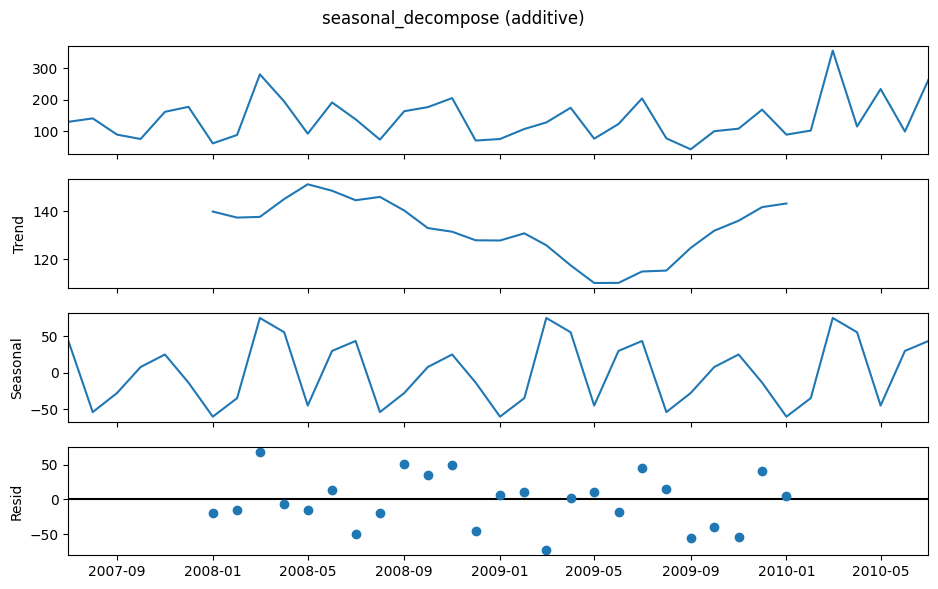

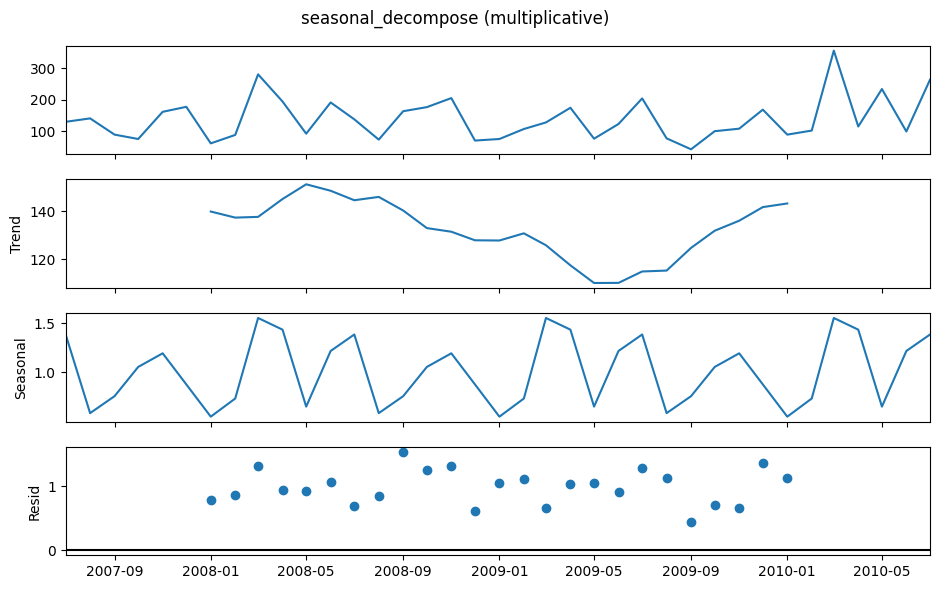

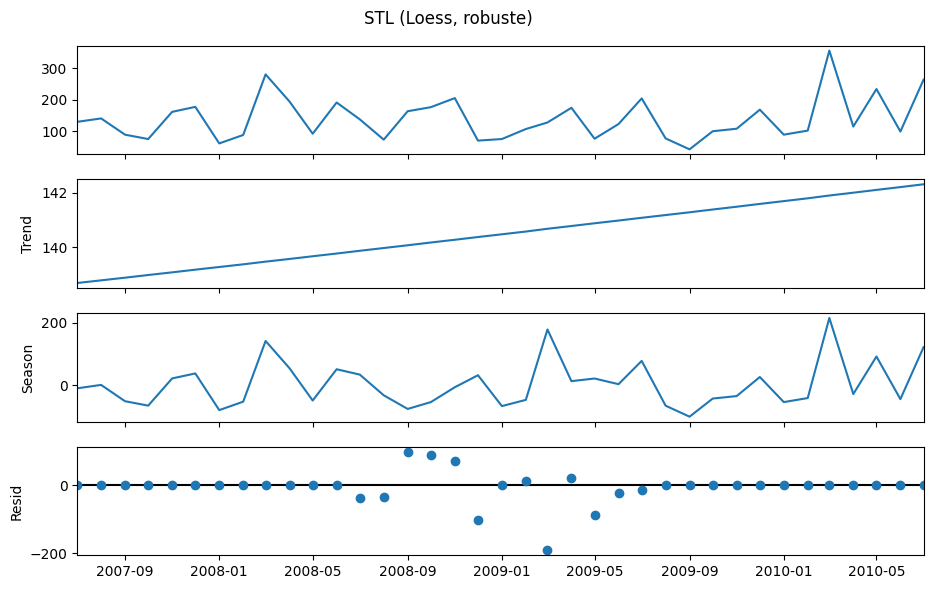

In [36]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

def show_decomp(res, title):
    fig = res.plot()
    fig.set_size_inches(10, 6)
    fig.axes[0].set_title('')      # sinon le nom de la série chevauche le suptitle
    fig.suptitle(title, y=0.99)
    fig.subplots_adjust(top=0.93)
    plt.show()

for mode in ['additive', 'multiplicative']:
    show_decomp(seasonal_decompose(ts, model=mode, period=12), f'seasonal_decompose ({mode})')

show_decomp(STL(ts, period=12, robust=True).fit(), 'STL (Loess, robuste)')

### Stationnarité

Tests ADF (H0 : racine unitaire) et KPSS (H0 : stationnaire) : stationnaire si ADF rejette et KPSS non.

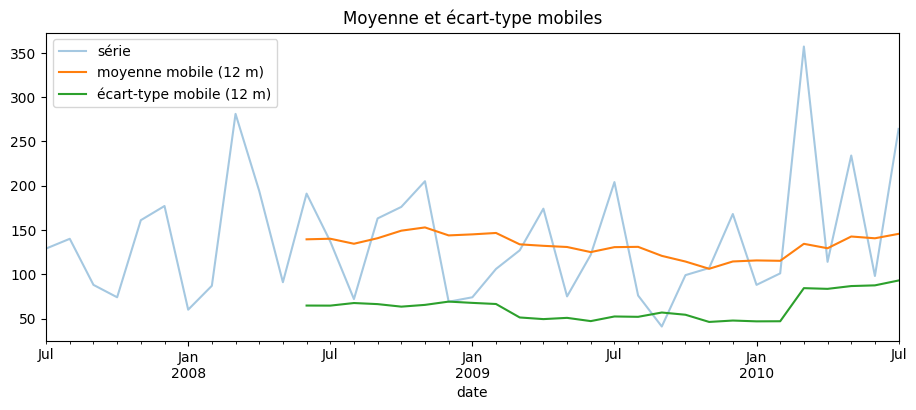

ADF p=0.000 (H0: racine unitaire) | KPSS p=0.100 (H0: stationnaire)


In [37]:
from statsmodels.tsa.stattools import adfuller, kpss

ax = ts.plot(figsize=(11, 4), alpha=.4, label='série')
ts.rolling(12).mean().plot(ax=ax, label='moyenne mobile (12 m)')
ts.rolling(12).std().plot(ax=ax, label='écart-type mobile (12 m)')
ax.set_title('Moyenne et écart-type mobiles'); ax.legend(); plt.show()

def stationnarite(s):
    return adfuller(s)[1], kpss(s, nlags='auto')[1]

p_adf, p_kpss = stationnarite(ts.dropna())
print(f'ADF p={p_adf:.3f} (H0: racine unitaire) | KPSS p={p_kpss:.3f} (H0: stationnaire)');

### Différenciation

Opérateur $\nabla=(1-B)$ : on différencie puis on re-teste la stationnarité.

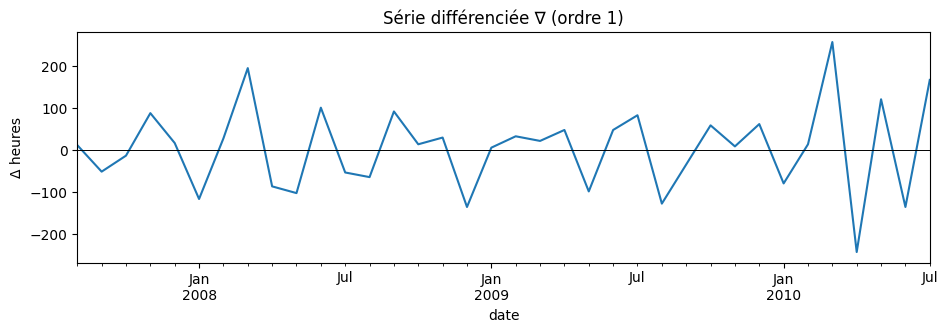

ADF p=0.000 | KPSS p=0.100
std brute = 69.2
std diff  = 102.0
ACF lag1 brute = -0.1
ACF lag1 diff  = -0.47


In [38]:
ts_diff = ts.diff().dropna()

ts_diff.plot(figsize=(11, 3), title='Série différenciée ∇ (ordre 1)')
plt.axhline(0, color='k', lw=.7); plt.ylabel('Δ heures'); plt.show()

p_adf, p_kpss = stationnarite(ts_diff)
print(f'ADF p={p_adf:.3f} | KPSS p={p_kpss:.3f}')

from statsmodels.tsa.stattools import acf
ts_diff = ts.diff().dropna()
print('std brute =', round(ts.std(), 1))
print('std diff  =', round(ts_diff.std(), 1))
print('ACF lag1 brute =', round(acf(ts, nlags=1)[1], 2))
print('ACF lag1 diff  =', round(acf(ts_diff, nlags=1)[1], 2))


### ACF / PACF

Série brute et différenciée ; la PACF fixe l'ordre $p$ de l'AR.

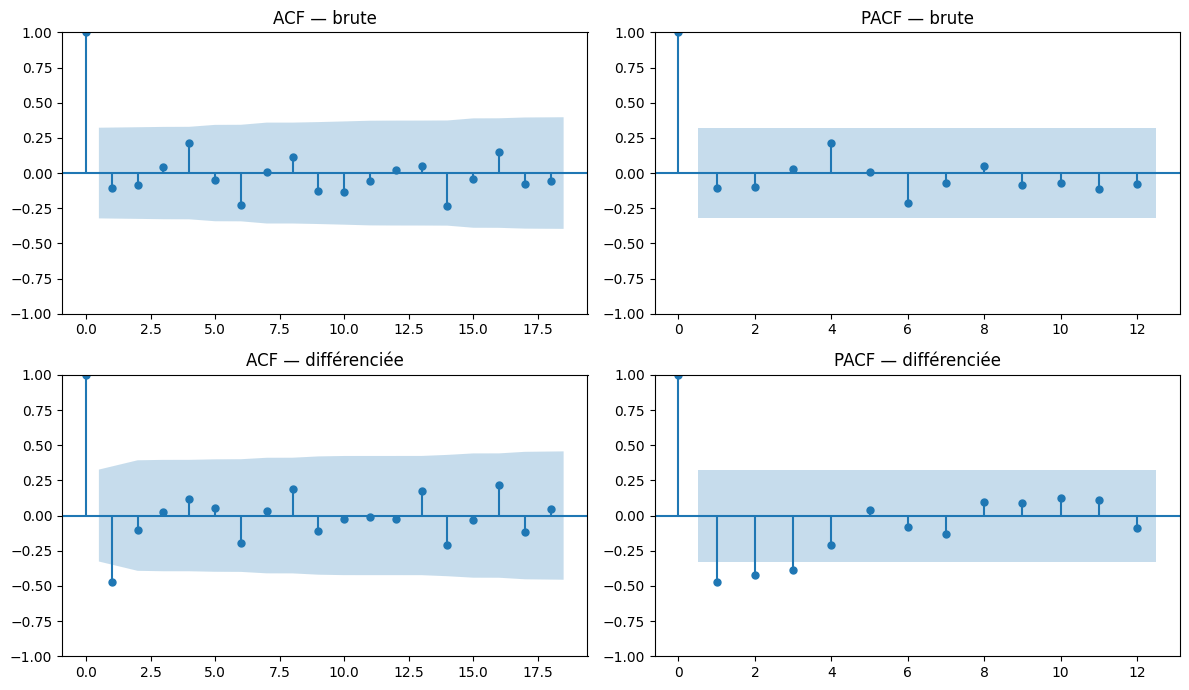

In [39]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(ts,       ax=ax[0, 0], lags=18, title='ACF — brute')
plot_pacf(ts,      ax=ax[0, 1], lags=12, method='ywm', title='PACF — brute')
plot_acf(ts_diff,  ax=ax[1, 0], lags=18, title='ACF — différenciée')
plot_pacf(ts_diff, ax=ax[1, 1], lags=12, method='ywm', title='PACF — différenciée')
plt.tight_layout(); plt.show()

## Mois de pic : quels motifs ?

Répartition des motifs (codes CIM/ICD) sur le mois de plus forte absence.

Table des motifs (code CIM/ICD → libellé) :

In [40]:
reason_map = {
    0: "Inconnu / non renseigné",
    1: "Certaines maladies infectieuses et parasitaires",
    2: "Tumeurs (néoplasmes)",
    3: "Maladies du sang et du système immunitaire",
    4: "Maladies endocriniennes, nutritionnelles et métaboliques",
    5: "Troubles mentaux et du comportement",
    6: "Maladies du système nerveux",
    7: "Maladies de l'œil et des annexes",
    8: "Maladies de l'oreille et de l'apophyse mastoïde",
    9: "Maladies de l'appareil circulatoire",
    10: "Maladies de l'appareil respiratoire",
    11: "Maladies de l'appareil digestif",
    12: "Maladies de la peau et du tissu sous-cutané",
    13: "Maladies du système musculo-squelettique et du tissu conjonctif",
    14: "Maladies de l'appareil génito-urinaire",
    15: "Grossesse, accouchement et suites de couches",
    16: "Certaines affections périnatales",
    17: "Malformations congénitales et anomalies chromosomiques",
    18: "Symptômes et résultats cliniques non classés ailleurs",
    19: "Traumatismes, intoxications et causes externes",
    20: "Causes externes de morbidité et mortalité",
    21: "Facteurs influençant l'état de santé et recours aux services de santé",
    22: "Suivi médical",
    23: "Consultation médicale",
    24: "Don du sang",
    25: "Examen de laboratoire",
    26: "Absence injustifiée",
    27: "Physiothérapie",
    28: "Consultation dentaire"
}

In [41]:
march = df[df['Month of absence'] == 3].copy()
march['Reason_label'] = march['Reason for absence'].map(reason_map)
march.groupby(march['date'].dt.to_period('M'))['Reason_label'].value_counts()

date     Reason_label                                                         
2008-03  Maladies du système musculo-squelettique et du tissu conjonctif           7
         Consultation dentaire                                                     4
         Maladies de l'appareil génito-urinaire                                    4
         Maladies de l'appareil digestif                                           4
         Traumatismes, intoxications et causes externes                            2
         Consultation médicale                                                     2
         Malformations congénitales et anomalies chromosomiques                    1
         Suivi médical                                                             1
         Certaines maladies infectieuses et parasitaires                           1
         Absence injustifiée                                                       1
         Maladies du système nerveux                                   

In [42]:
(df.assign(Reason_label=df['Reason for absence'].map(reason_map))
   .groupby([df['date'].dt.to_period('M'), 'Reason_label'])['Absenteeism time in hours'].sum()
   .loc['2010-03'].sort_values(ascending=False))

Reason_label
Maladies de la peau et du tissu sous-cutané                        112
Traumatismes, intoxications et causes externes                     112
Physiothérapie                                                      41
Maladies du système musculo-squelettique et du tissu conjonctif     36
Consultation médicale                                               23
Examen de laboratoire                                               13
Maladies de l'œil et des annexes                                     8
Suivi médical                                                        8
Maladies de l'appareil respiratoire                                  4
Name: Absenteeism time in hours, dtype: int64

### Conclusion : mélange d'accidents + maladies

# 3) Prévision (forecasting)

Anticiper le volume mensuel d'heures. Série stationnaire → $d=0$ ; comparaison baselines / AR / MA / ARMA (MAE-RMSE + résidus).

In [43]:
from statsmodels.tsa.arima.model import ARIMA
import warnings; warnings.filterwarnings('ignore')

ts = ts.astype(float)
H = 9
train, test = ts.iloc[:-H], ts.iloc[-H:]
print(f'train {len(train)} mois ({train.index.min():%Y-%m} → {train.index.max():%Y-%m}) | test {len(test)} mois')

def mae(y, yhat):  return float(np.mean(np.abs(np.asarray(y, float) - np.asarray(yhat, float))))
def rmse(y, yhat): return float(np.sqrt(np.mean((np.asarray(y, float) - np.asarray(yhat, float))**2)))

baselines = {
    'moyenne'         : np.repeat(train.mean(), H),
    'naïf (dernière)' : np.repeat(train.iloc[-1], H),
    'naïf saisonnier' : ts.shift(12).iloc[-H:].values,
}
scores = {name: (mae(test, p), rmse(test, p)) for name, p in baselines.items()}
pd.DataFrame(scores, index=['MAE', 'RMSE']).T.round(1)

train 28 mois (2007-07 → 2009-10) | test 9 mois


,MAE,RMSE
moyenne,71.5,98.5
naïf (dernière),73.8,114.1
naïf saisonnier,83.2,108.3


### AR($p$) — autorégression

$p$ = dernier lag significatif de la PACF, estimé par MLE.

In [44]:
from statsmodels.tsa.stattools import pacf

# p = dernier lag PACF significatif
pv = pacf(train, nlags=12, method='ywm')
ci = 1.96 / np.sqrt(len(train))
p = max([k for k in range(1, 7) if abs(pv[k]) > ci] or [1])

ar_fit  = ARIMA(train, order=(p, 0, 0)).fit()
ar_pred = ar_fit.forecast(H)
scores[f'AR({p})'] = (mae(test, ar_pred), rmse(test, ar_pred))
print(f'p={p} | AR({p}) -> MAE {scores[f"AR({p})"][0]:.1f} | RMSE {scores[f"AR({p})"][1]:.1f}')

p=2 | AR(2) -> MAE 70.6 | RMSE 96.3


### MA($q$) — moyenne mobile

$q$ = dernier lag significatif de l'ACF, estimé par MLE.

In [45]:
from statsmodels.tsa.stattools import acf

# q = dernier lag ACF significatif
av = acf(train, nlags=12)
q = max([k for k in range(1, 7) if abs(av[k]) > ci] or [1])
ma_fit  = ARIMA(train, order=(0, 0, q)).fit()
ma_pred = ma_fit.forecast(H)
scores[f'MA({q})'] = (mae(test, ma_pred), rmse(test, ma_pred))
print(f'q={q} | MA({q}) -> MAE {scores[f"MA({q})"][0]:.1f} | RMSE {scores[f"MA({q})"][1]:.1f}')

q=2 | MA(2) -> MAE 70.6 | RMSE 97.7


### ARMA($p,0,q$) — Box-Jenkins

Balayage de la grille $(p,q)$, sélection par BIC (AIC en contrôle).

In [46]:
d = 0  # série déjà stationnaire
grid = []
for pp in range(4):
    for qq in range(4):
        try:
            res = ARIMA(train, order=(pp, d, qq)).fit()
            fc = res.forecast(H)
            grid.append({'order': (pp, d, qq), 'AIC': res.aic, 'BIC': res.bic,
                         'MAE': mae(test, fc), 'RMSE': rmse(test, fc)})
        except Exception:
            pass

grid = pd.DataFrame(grid).sort_values('BIC').reset_index(drop=True)
best_order = grid.loc[0, 'order']
print(f'Ordre retenu (BIC min) : ARIMA{best_order}')
grid.round(1)

Ordre retenu (BIC min) : ARIMA(0, 0, 2)


,order,AIC,BIC,MAE,RMSE
0,"(0, 0, 2)",304.1,309.4,70.6,97.7
1,"(2, 0, 0)",305.4,310.8,70.6,96.3
2,"(2, 0, 1)",305.0,311.7,70.5,97.4
3,"(0, 0, 0)",309.2,311.9,71.5,98.5
4,"(0, 0, 3)",306.1,312.7,70.7,97.7
5,"(1, 0, 2)",306.1,312.7,70.6,97.7
6,"(3, 0, 0)",306.1,312.8,71.8,96.8
7,"(1, 0, 1)",307.6,312.9,70.0,98.3
8,"(0, 0, 1)",309.3,313.3,70.7,98.6
9,"(1, 0, 3)",306.6,314.6,72.1,97.1


### Comparaison aux baselines

Tous les modèles sur le test (MAE/RMSE) ; référence : la meilleure baseline.

In [47]:
arima_fit  = ARIMA(train, order=best_order).fit()
arima_pred = arima_fit.forecast(H)
scores[f'ARIMA{best_order}'] = (mae(test, arima_pred), rmse(test, arima_pred))

best_baseline = min(scores[k][1] for k in baselines)
recap = pd.DataFrame(scores, index=['MAE', 'RMSE']).T.sort_values('RMSE').round(1)
recap['bat baseline'] = recap['RMSE'] < best_baseline
recap

,MAE,RMSE,bat baseline
AR(2),70.6,96.3,True
MA(2),70.6,97.7,True
"ARIMA(0, 0, 2)",70.6,97.7,True
moyenne,71.5,98.5,True
naïf saisonnier,83.2,108.3,False
naïf (dernière),73.8,114.1,False


### Diagnostic des résidus (Box-Jenkins)

Résidus = bruit blanc si ACF plate et Ljung-Box $p>0{,}05$.

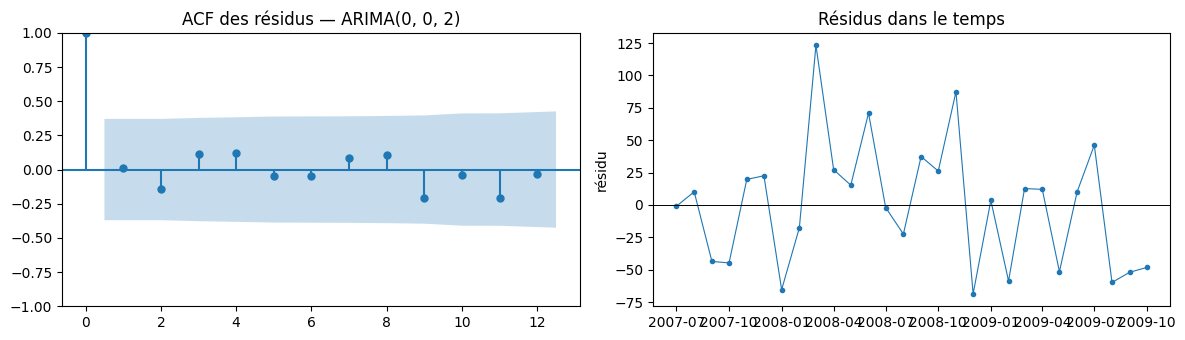

    lb_stat  lb_pvalue
6     1.802      0.937
12    6.744      0.874
-> résidus ≈ bruit blanc.


In [48]:
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = arima_fit.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(resid, ax=axes[0], lags=12, title=f'ACF des résidus — ARIMA{best_order}')
axes[1].plot(resid.index, resid.values, marker='.', lw=.8)
axes[1].axhline(0, color='k', lw=.7)
axes[1].set_title('Résidus dans le temps'); axes[1].set_ylabel('résidu')
plt.tight_layout(); plt.show()

lb = acorr_ljungbox(resid, lags=[6, 12], return_df=True)
print(lb.round(3))
print('-> résidus ≈ bruit blanc.' if (lb['lb_pvalue'] > .05).all() else '-> autocorrélation résiduelle.')

### Résultats

(a) Prévision sur le test avec IC 95 % ; (b) projection des 12 mois suivants.

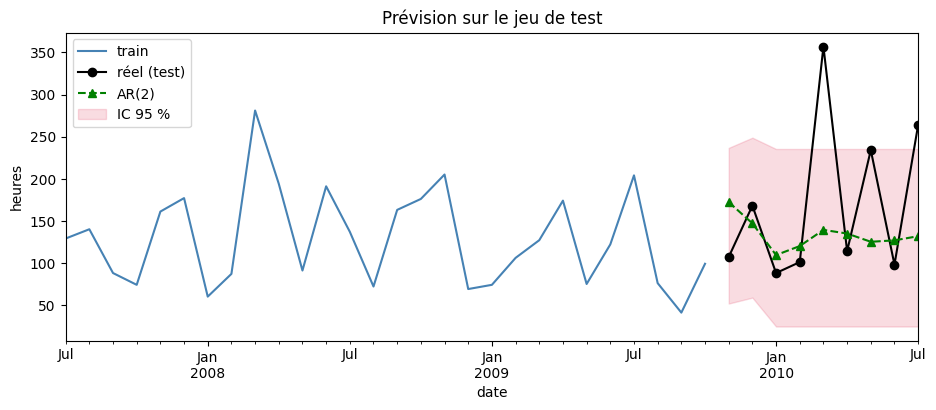

In [49]:
# (a) prévision sur le test avec IC 95 %
ci = arima_fit.get_forecast(H).conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 4))
train.plot(ax=ax, color='steelblue', label='train')
test.plot(ax=ax, color='black', marker='o', label='réel (test)')
ar_pred.plot(ax=ax, color='green', ls='--', marker='^', label=f'AR({p})')
ax.fill_between(arima_pred.index, ci.iloc[:, 0], ci.iloc[:, 1], color='crimson', alpha=.15, label='IC 95 %')
ax.set_title('Prévision sur le jeu de test'); ax.set_ylabel('heures'); ax.legend(); plt.show()

**Conclusion.** Modèles à peine meilleurs que la moyenne, résidus ≈ bruit blanc → pivot vers l'approche explicative.

# 4) Effet du jour de la semaine

Effet du jour (lundi→vendredi) sur le volume d'heures, testé par Kruskal-Wallis ; valider le jour comme prédicteur.

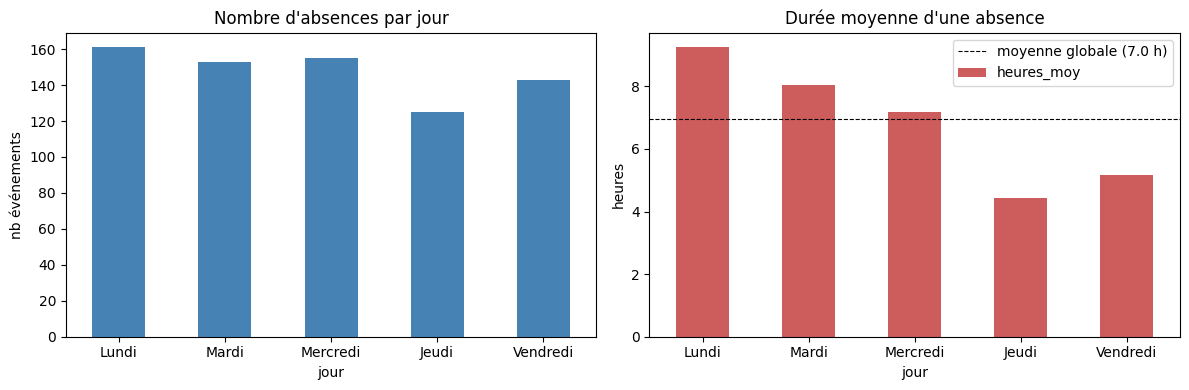

Kruskal-Wallis (heures ~ jour) : H=10.7, p=0.030


,nb_absences,heures_totales,heures_moy
jour,,,
Lundi,161,1489,9.2
Mardi,153,1229,8.0
Mercredi,155,1115,7.2
Jeudi,125,553,4.4
Vendredi,143,738,5.2


In [50]:
from scipy import stats

dow   = {2: 'Lundi', 3: 'Mardi', 4: 'Mercredi', 5: 'Jeudi', 6: 'Vendredi'}
order = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi']
h     = 'Absenteeism time in hours'
df['jour'] = df['Day of the week'].map(dow)

stat = (df.groupby('jour')
          .agg(nb_absences=(h, 'size'), heures_totales=(h, 'sum'), heures_moy=(h, 'mean'))
          .reindex(order))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stat['nb_absences'].plot.bar(ax=ax[0], color='steelblue')
ax[0].set_title("Nombre d'absences par jour"); ax[0].set_ylabel('nb événements'); ax[0].tick_params(axis='x', rotation=0)
stat['heures_moy'].plot.bar(ax=ax[1], color='indianred')
ax[1].axhline(df[h].mean(), color='k', ls='--', lw=.8, label=f'moyenne globale ({df[h].mean():.1f} h)')
ax[1].set_title("Durée moyenne d'une absence"); ax[1].set_ylabel('heures'); ax[1].tick_params(axis='x', rotation=0); ax[1].legend()
plt.tight_layout(); plt.show()

kw = stats.kruskal(*[g[h].values for _, g in df.groupby('jour')])
print(f'Kruskal-Wallis (heures ~ jour) : H={kw.statistic:.1f}, p={kw.pvalue:.3f}')
stat.round(1)

### Risque d'absence « longue »

Cible binaire (> 8 h) ; test du $\chi^2$ d'indépendance (H0 : jour ⊥ absence longue).

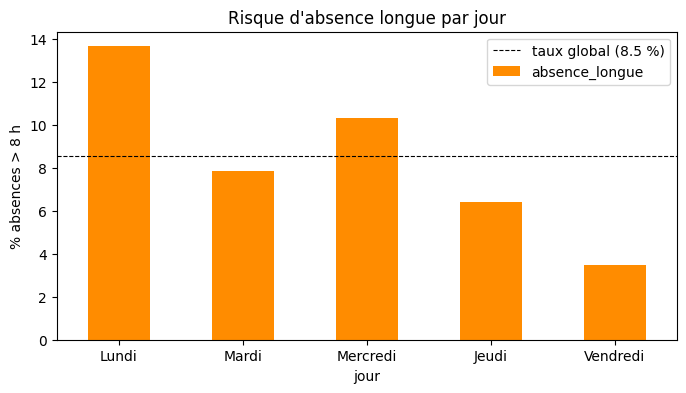

χ² (jour × absence longue) : χ²=11.52, ddl=4, p=0.0213 -> dépend du jour


In [51]:
df['absence_longue'] = (df[h] > 8).astype(int)
taux = df.groupby('jour')['absence_longue'].mean().reindex(order) * 100

ax = taux.plot.bar(figsize=(8, 4), color='darkorange')
ax.axhline(df['absence_longue'].mean() * 100, color='k', ls='--', lw=.8,
           label=f'taux global ({df["absence_longue"].mean()*100:.1f} %)')
ax.set_ylabel('% absences > 8 h'); ax.set_title("Risque d'absence longue par jour")
ax.tick_params(axis='x', rotation=0); ax.legend(); plt.show()

ct = pd.crosstab(df['jour'], df['absence_longue']).reindex(order)
chi2, p_chi, dof, _ = stats.chi2_contingency(ct)
print(f'χ² (jour × absence longue) : χ²={chi2:.2f}, ddl={dof}, p={p_chi:.4f}',
      '-> dépend du jour' if p_chi < 0.05 else '-> indépendant')

# 5) Classification : durée d'absence (3 classes)

Classer low (≤4h) / mod (5-8h) / high (>8h). Classes déséquilibrées → macro-F1, balanced accuracy, ROC-AUC (ovr).

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (f1_score, roc_auc_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

# cible 3 classes : low (<=4 h) / mod (5-8 h) / high (>8 h)
df['classe'] = pd.cut(df[h], [-1, 4, 8, 1e9], labels=[0, 1, 2]).astype(int)
labels3 = ['low (<=4h)', 'mod (5-8h)', 'high (>8h)']

cat  = ['Reason for absence', 'Day of the week', 'Seasons', 'Education']
num  = ['Transportation expense', 'Distance from Residence to Work', 'Service time', 'Age',
        'Work load Average/day ', 'Hit target', 'Son', 'Pet', 'Body mass index']
binr = ['Disciplinary failure', 'Social drinker', 'Social smoker']

Xf = df[cat + num + binr]
yv = df['classe']
print('répartition :', dict(yv.value_counts().sort_index()))

pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat),
    ('num', StandardScaler(), num),
], remainder='passthrough')

Xtr, Xte, ytr, yte = train_test_split(Xf, yv, test_size=0.25, stratify=yv, random_state=42)

répartition : {0: np.int64(458), 1: np.int64(216), 2: np.int64(63)}


### Séparabilité des classes

Projection PCA 2D : un fort chevauchement expliquerait la difficulté de classification.

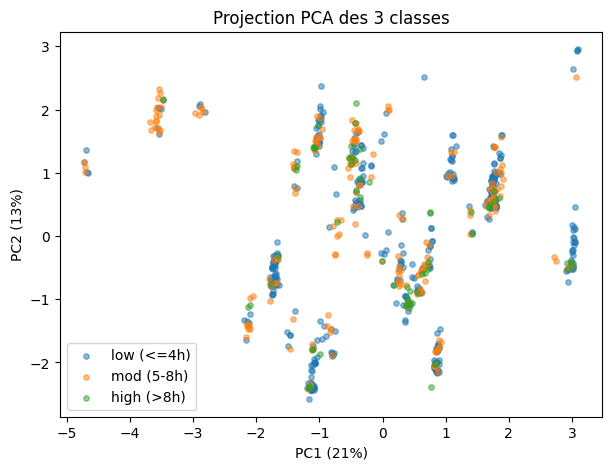

In [53]:
from sklearn.decomposition import PCA
from sklearn.base import clone

Xp = clone(pre).fit_transform(Xf)
Xp = Xp.toarray() if hasattr(Xp, 'toarray') else Xp
pca = PCA(n_components=2).fit(Xp)
Z = pca.transform(Xp)

fig, ax = plt.subplots(figsize=(7, 5))
for k, lab in enumerate(labels3):
    m = yv.values == k
    ax.scatter(Z[m, 0], Z[m, 1], s=15, alpha=.5, label=lab)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
ax.set_title('Projection PCA des 3 classes'); ax.legend(); plt.show()

### Modèles comparés

Baseline, régression logistique, arbre, SVM, Random Forest ; métrique principale : macro-F1 en CV.

In [54]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

models = {
    'Baseline (majoritaire)': DummyClassifier(strategy='most_frequent'),
    'Régression logistique' : LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Arbre de décision'     : DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'SVM'                   : SVC(class_weight='balanced', probability=True, random_state=42),
    'Random Forest'         : RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)

rows, fitted = {}, {}
for name, clf in models.items():
    pipe = Pipeline([('pre', pre), ('clf', clf)])
    cv_f1 = cross_val_score(pipe, Xf, yv, cv=cv, scoring='f1_macro').mean()
    pipe.fit(Xtr, ytr)
    fitted[name] = pipe
    proba = pipe.predict_proba(Xte) 
    pred = pipe.predict(Xte)
    rows[name] = {'CV F1-macro': cv_f1, 'test F1-macro': f1_score(yte, pred, average='macro'),
                  'test ROC-AUC (ovr)': roc_auc_score(yte, proba, multi_class='ovr', average='macro'),
                  'test bal-acc': balanced_accuracy_score(yte, pred)}

pd.DataFrame(rows).T.round(3)

,CV F1-macro,test F1-macro,test ROC-AUC (ovr),test bal-acc
Baseline (majoritaire),0.256,0.256,0.500,0.333
Régression logistique,0.611,0.592,0.823,0.636
Arbre de décision,0.525,0.469,0.642,0.473
SVM,0.576,0.560,0.842,0.586
Random Forest,0.585,0.569,0.845,0.559


### Matrice de confusion et rapport par classe

Meilleur modèle (macro-F1) : matrice 3×3 + précision/rappel/F1 par classe.

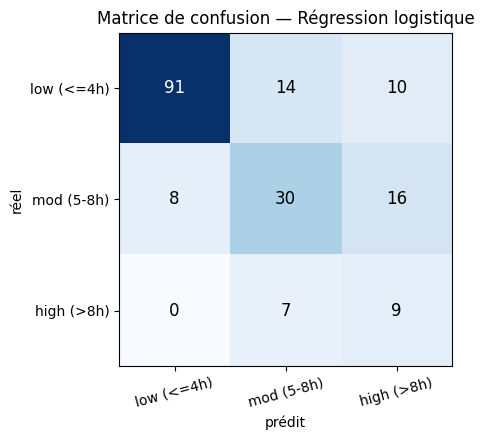

Meilleur modèle (CV F1-macro) : Régression logistique

              precision    recall  f1-score   support

  low (<=4h)       0.92      0.79      0.85       115
  mod (5-8h)       0.59      0.56      0.57        54
  high (>8h)       0.26      0.56      0.35        16

    accuracy                           0.70       185
   macro avg       0.59      0.64      0.59       185
weighted avg       0.77      0.70      0.73       185



In [55]:
best_name = max(rows, key=lambda n: rows[n]['CV F1-macro'])
best = fitted[best_name]
pred = best.predict(Xte)

cm = confusion_matrix(yte, pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black', fontsize=12)
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels(labels3, rotation=15); ax.set_yticklabels(labels3)
ax.set_xlabel('prédit'); ax.set_ylabel('réel'); ax.set_title(f'Matrice de confusion — {best_name}')
plt.tight_layout(); plt.show()

print(f'Meilleur modèle (CV F1-macro) : {best_name}\n')
print(classification_report(yte, pred, target_names=labels3, zero_division=0))

### Variables les plus discriminantes

Importances du Random Forest + poids cumulé du jour de la semaine.

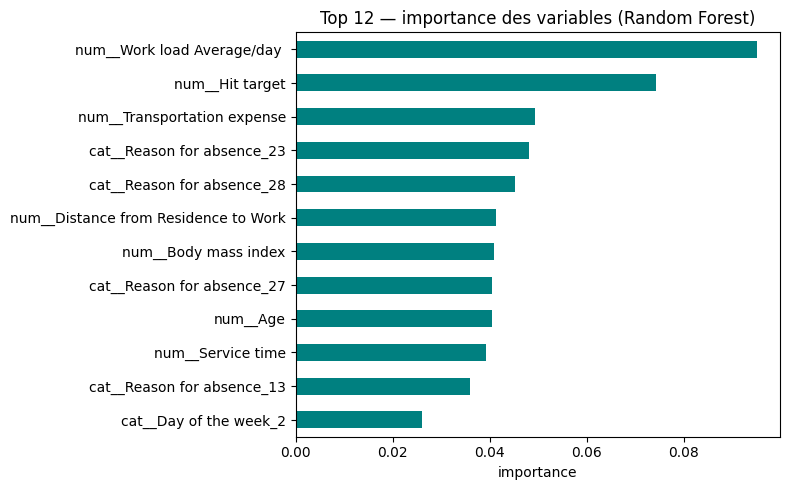

Poids cumulé du 'jour de la semaine' : 10.0% de l'importance totale.


In [56]:
rf = fitted['Random Forest']
feat_names = rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=feat_names).sort_values()

ax = imp.tail(12).plot.barh(figsize=(8, 5), color='teal')
ax.set_title('Top 12 — importance des variables (Random Forest)')
ax.set_xlabel('importance'); plt.tight_layout(); plt.show()

poids_jour = imp[[n for n in feat_names if 'Day of the week' in n]].sum()
print(f"Poids cumulé du 'jour de la semaine' : {poids_jour:.1%} de l'importance totale.")

### Conclusion

Meilleur macro-F1 : régression logistique (0,61) — un modèle simple rivalise avec le Random Forest. Classe *high* la plus dure (rare) : **difficulté intrinsèque aux données.**